# 07 Uneven distribution and unusual shapes: where does the error sit, and what happens to a shape the network has not seen?

**Question (REQ-007 and the bonus on unusual shapes).** The values of the plasma parameters are not spread evenly: most
rows are ordinary, a minority are limited plasmas, discharges with the opposite current sign, the first and last
moments of a discharge, or rare shapes. (1) How uneven are the targets? (2) Which groups of rows carry the error that
the headline mean hides? (3) What did we do about it, and what did it cost? (4) How much worse is the network on a family of
shapes it was not trained on?

This notebook is **data free**. It parses the numbers out of the aggregate files committed under `results/`
(`ipp1-data-checks.md`, `ipp1-distribution.md`, `ipp1-unusual-shapes.md`, `ipp1-signcanon.md`, `ipp1-final.md`); no IPP row is read
and nothing is trained, so it runs top to bottom on a clean checkout in a few seconds (needs `numpy pandas matplotlib`).
The measurements were made by the scripts in `analysis/` on the confidential data; each table below names the protocol it
comes from. Numbers in the text are generated from the parsed files.

Two protocols appear and are never mixed in one number:

| name | what it is | used for |
|---|---|---|
| **P1, out-of-fold** | baseline network (256-256-128, 24 inputs, 60 epochs), 5 folds split by whole discharge, predictions of the held-out discharges pooled over all 149 discharges (42,972 rows) | sections 2, 3 and 5 |
| **P2, development and set aside** | 119 development discharges (5 folds inside) and 30 discharges kept aside (8,761 rows), scored once per final model; recipes in `ipp1-final.md` | section 4 |

Errors are mean absolute differences (MAE) from the reference reconstruction (the institute's equilibrium reconstruction that gives the labels, not an independent measurement of the plasma) in the unit of the target: mm for positions, kA for the plasma current.

In [1]:
import re, json, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

# This notebook reads only files committed under results/ (tables, json, png); it needs no IPP data and no training.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "ipp1-final.md").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository: results/ipp1-final.md was not found")
RES = repo / "results"
READ = set()  # every results file this notebook opens, checked against `git ls-files` at the end


def read(name):
    READ.add(name)
    return (RES / name).read_text()


def num(x):
    """First number in a cell: '44.2%' -> 44.2, '1.2 [0.9, 1.4]' -> 1.2, '0.53 to 1.10 (2.1x)' -> 0.53, 'n/a' -> nan."""
    m = re.search(r"-?\d+(?:\.\d+)?(?:e[+-]?\d+)?", str(x).replace(",", ""))
    return float(m.group()) if m else np.nan


def md_tables(name):
    """All pipe tables of a results markdown file as (nearest heading above, DataFrame of strings)."""
    out, heading, cur = [], "", None
    for line in read(name).splitlines():
        if line.startswith("#"):
            heading, cur = line.lstrip("# ").strip(), None
        elif line.startswith("|"):
            cells = [c.strip() for c in line.strip().strip("|").split("|")]
            if cur is None:
                cur = {"heading": heading, "header": cells, "rows": []}
                out.append(cur)
            elif not set("".join(cells)) <= set("-: "):
                cur["rows"].append(cells)
        else:
            cur = None
    return [(t["heading"], pd.DataFrame(t["rows"], columns=t["header"])) for t in out]


def table(name, heading=None, has=None, nth=0):
    """The nth table whose heading starts with `heading` and whose header contains every column in `has`."""
    hits = [df for h, df in md_tables(name)
            if (heading is None or h.startswith(heading)) and all(c in df.columns for c in (has or []))]
    if len(hits) <= nth:
        raise KeyError(f"{name}: no table for heading={heading!r} has={has!r}")
    return hits[nth]


def numeric(df, text=("target", "unit")):
    """Index by the first column and turn every other column into floats (text columns kept as strings)."""
    df = df.copy()
    if "unit" in df.columns:
        df["unit"] = df["unit"].replace("", "-")  # dimensionless targets: the results files leave the cell empty
    for c in df.columns[1:]:
        if c not in text:
            df[c] = df[c].map(num).astype(float)
    return df.set_index(df.columns[0])


def section(name, heading):
    """Lines of the `## heading...` section (up to the next `## `), as written in the results file."""
    lines, on = [], False
    for line in read(name).splitlines():
        if line.startswith("## "):
            on = line[3:].startswith(heading)
            continue
        if on:
            lines.append(line)
    if not lines:
        raise KeyError(f"{name}: no section {heading!r}")
    return "\n".join(lines).strip()


def show(df, proto, fmt="{:.3g}"):
    """Print a table with the protocol it was measured under right above it."""
    print("Protocol:", proto)
    print(df.to_string(float_format=lambda v: fmt.format(v)))
    print()


def quote(text, source):
    display(Markdown(f"*Quoted from `results/{source}`:*\n\n" + text))


def tracked_check():
    """True when every results file opened above is under git version control (not a local scratch file)."""
    out = subprocess.run(["git", "-C", str(repo), "ls-files", "results"], capture_output=True, text=True)
    tracked = {Path(p).name for p in out.stdout.split()}
    missing = sorted(f for f in READ if f not in tracked)
    return missing, len(READ), bool(tracked)


print("repository:", repo.name, "| results folder:", RES.relative_to(repo))

repository: hackathon-cloud | results folder: results


## 1. How uneven are the targets?

`ipp1-data-checks.md` gives for each target the standard deviation and the width of the band that holds 98 % of the values.
If the values were normally distributed, that band would be 4.65 standard deviations wide. A band much narrower than that
means a few rare values stretch the standard deviation. The ratio is our own division of the two committed columns.

Protocol: all 149 discharges, every row where the target exists (aggregate of `analysis/ipp1_data_checks.py`)
                    unit  standard deviation  98 percent band width  band_over_sd
target                                                                           
plasma_current        kA                 114                    543          4.75
R_mag_axis            mm                8.02                   42.3          5.27
Z_mag_axis            mm                13.7                   56.4          4.11
elongation             -               0.271                  0.836          3.09
triangularity          -               0.119                  0.424          3.55
triangularity_upper    -              0.0749                    0.3             4
triangularity_lower    -               0.172                  0.598          3.47
R_x_point             mm                8.06                   38.2          4.74
Z_x_point             mm                12.7                   49.9   

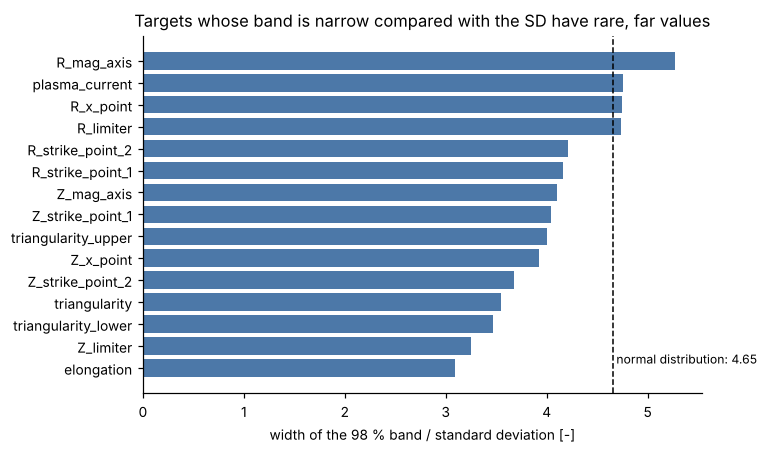

**Reading.** The spread is small only for the magnetic axis, the X-point and the strike points: standard deviation 2.4 to 13.7 mm. The limiter point moves by 90 mm (R) and 153 mm (Z) and the plasma current by 114 kA, so errors are always given in physical units and next to the spread. 98 % of the axis values lie in a band 42.3 mm wide (R) and 56.4 mm wide (Z). The standard deviation of the elongation is 1.51 times what its 98 % band implies: consistent with a small group of discharges that have a very different shape (section 5).

In [2]:
F_CHK = "ipp1-data-checks.md"
spread = numeric(table(F_CHK, "Spread of the targets"))
spread["band_over_sd"] = spread["98 percent band width"] / spread["standard deviation"]
show(spread, "all 149 discharges, every row where the target exists (aggregate of `analysis/ipp1_data_checks.py`)")

fig, ax = plt.subplots(figsize=(7, 4.2))
order = spread["band_over_sd"].sort_values().index
ax.barh(order, spread.loc[order, "band_over_sd"], color="#4c78a8")
ax.axvline(4.653, color="k", ls="--", lw=1)
ax.text(4.69, 0.2, "normal distribution: 4.65", fontsize=8)
ax.set_xlabel("width of the 98 % band / standard deviation [-]")
ax.set_title("Targets whose band is narrow compared with the SD have rare, far values")
plt.tight_layout(); plt.show()

small = ["R_mag_axis", "Z_mag_axis", "R_x_point", "Z_x_point", "R_strike_point_1", "Z_strike_point_1", "R_strike_point_2", "Z_strike_point_2"]
sd_small = spread.loc[small, "standard deviation"]
display(Markdown(
    f"**Reading.** The spread is small only for the magnetic axis, the X-point and the strike points: standard deviation "
    f"{sd_small.min():.1f} to {sd_small.max():.1f} mm. The limiter point moves by {spread.loc['R_limiter','standard deviation']:.0f} mm (R) and "
    f"{spread.loc['Z_limiter','standard deviation']:.0f} mm (Z) and the plasma current by {spread.loc['plasma_current','standard deviation']:.0f} kA, "
    f"so errors are always given in physical units and next to the spread. 98 % of the axis values lie in a band "
    f"{spread.loc['R_mag_axis','98 percent band width']:.1f} mm wide (R) and {spread.loc['Z_mag_axis','98 percent band width']:.1f} mm wide (Z). "
    f"The standard deviation of the elongation is {1/spread.loc['elongation','band_over_sd']*4.653:.2f} times what its 98 % band implies: "
    f"consistent with a small group of discharges that have a very different shape (section 5)."))

## 2. Where the error sits (protocol P1)

Source: `ipp1-distribution.md`, made by `analysis/ipp1_distribution.py` from the out-of-fold predictions of the baseline network.
Nothing is trained here. Every group is shown with two shares: `rows` is its share of the rows and `sq err` its share of the total
squared error of that target. Where `sq err` is far above `rows`, a minority carries the error.

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); mean, median and tail percentiles of the absolute error
                 unit     MAE  median    p95   p99   max  nRMSE
target                                                         
plasma_current     kA    1.49   0.747   4.38  15.9  91.4 0.0297
R_mag_axis         mm   0.377   0.153   1.21  3.74  64.3  0.156
Z_mag_axis         mm   0.391    0.18   1.33  3.55   284  0.125
elongation          - 0.00569 0.00301 0.0188 0.044 0.493 0.0429
R_x_point          mm   0.203  0.0755  0.615  3.15  20.5 0.0774
R_strike_point_1   mm   0.265   0.112  0.754  3.55  15.1 0.0653
R_limiter          mm    10.8    2.64     49   145   378  0.318
Z_limiter          mm    22.3    9.32   90.9   171   512  0.273



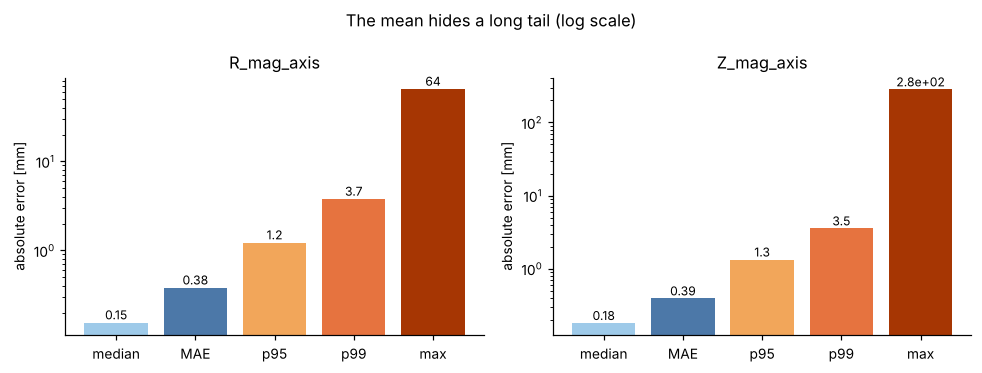

In [3]:
F_DIST = "ipp1-distribution.md"
P1 = ("baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges "
      "(`ipp1-distribution.md`)")
overall = numeric(table(F_DIST, "Overall, for reference"))
head = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_strike_point_1", "R_limiter", "Z_limiter"]
show(overall.loc[head, ["unit", "MAE", "median", "p95", "p99", "max", "nRMSE"]], P1 + "; mean, median and tail percentiles of the absolute error")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, t in zip(axes, ["R_mag_axis", "Z_mag_axis"]):
    vals = overall.loc[t, ["median", "MAE", "p95", "p99", "max"]]
    ax.bar(vals.index, vals.values, color=["#9ecae9", "#4c78a8", "#f2a65a", "#e6733f", "#a63603"])
    ax.set_yscale("log"); ax.set_title(t); ax.set_ylabel("absolute error [mm]")
    for i, v in enumerate(vals.values): ax.text(i, v * 1.1, f"{v:.2g}", ha="center", fontsize=8)
plt.suptitle("The mean hides a long tail (log scale)"); plt.tight_layout(); plt.show()

### 2.1 Limited against diverted plasma

The plasma is either diverted (has an X-point and strike points) or limited (touches the wall at the limiter point).
Limited rows are the minority and the harder case.

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); limited = `is_limited` of the reference reconstruction; rows and sq err in %
                    unit  MAE limited  MAE diverted  rows limited  sq err limited  MAE ratio limited/diverted
target                                                                                                       
plasma_current        kA         2.01          1.07          44.2            77.9                        1.88
R_mag_axis            mm        0.553         0.237          44.2            91.9                        2.33
Z_mag_axis            mm        0.516         0.293          44.2            94.3                        1.76
elongation             -      0.00815       0.00373          44.2            80.4                        2.18
triangularity          -      0.00415        0.0018          44.2            84.1                     

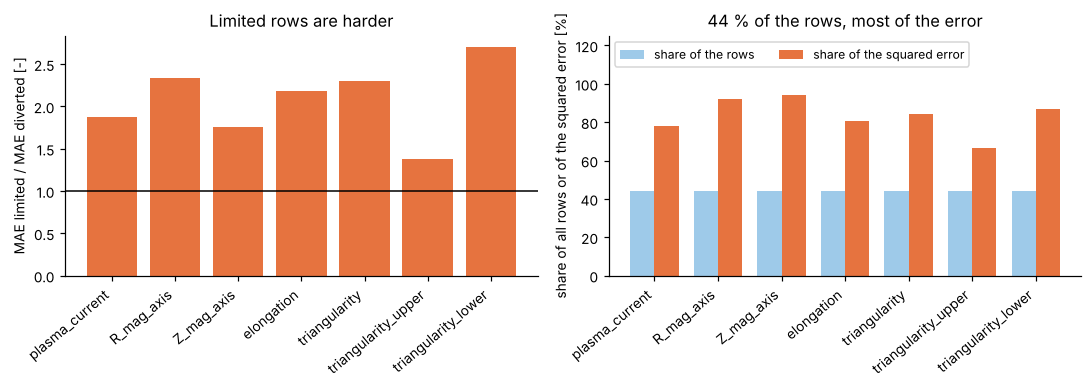

In [4]:
cfg = numeric(table(F_DIST, "By configuration"))
t7 = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "triangularity", "triangularity_upper", "triangularity_lower"]
c = cfg.loc[t7, ["unit", "MAE limited", "MAE diverted", "rows limited", "sq err limited"]].copy()
c["MAE ratio limited/diverted"] = c["MAE limited"] / c["MAE diverted"]
show(c, P1 + "; limited = `is_limited` of the reference reconstruction; rows and sq err in %")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].bar(c.index, c["MAE ratio limited/diverted"], color="#e6733f"); axes[0].axhline(1, color="k", lw=1)
axes[0].set_ylabel("MAE limited / MAE diverted [-]"); axes[0].set_title("Limited rows are harder")
x = np.arange(len(c)); w = 0.38
axes[1].bar(x - w/2, c["rows limited"], w, label="share of the rows", color="#9ecae9")
axes[1].bar(x + w/2, c["sq err limited"], w, label="share of the squared error", color="#e6733f")
axes[1].set_ylabel("share of all rows or of the squared error [%]"); axes[1].set_title(f"{c['rows limited'].iloc[0]:.0f} % of the rows, most of the error"); axes[1].set_ylim(0, 125); axes[1].legend(fontsize=8, ncol=2, loc="upper left")
for ax in axes: ax.set_xticks(range(len(c))); ax.set_xticklabels(c.index, rotation=40, ha="right")
plt.tight_layout(); plt.show()

### 2.2 Reversed (positive) plasma current

16 of the 149 discharges have a positive plasma current in the file, all others a negative one (`positive current` below; 92.6 % of the rows are negative). The sign convention and its relation to the toroidal field are not recorded in this repository, so we do not know whether these are discharges of opposite machine polarity; 'reversed' below only means 'positive sign'.
The folds were not stratified on polarity, so these 16 discharges are also unevenly spread over the folds.

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); reversed = positive mean plasma current (16 discharges), usual = negative
                 unit  MAE reversed  MAE usual  rows reversed %  sq err reversed %  MAE ratio reversed/usual
target                                                                                                      
plasma_current     kA          3.62       1.32              7.4                 26                      2.74
R_mag_axis         mm          1.73      0.269              7.4               77.8                      6.43
Z_mag_axis         mm          1.38      0.312              7.4               86.6                      4.42
elongation          -        0.0174    0.00475              7.4               51.6                      3.66
R_x_point          mm          1.36      0.123              6.4               83.8                      11.1
R_

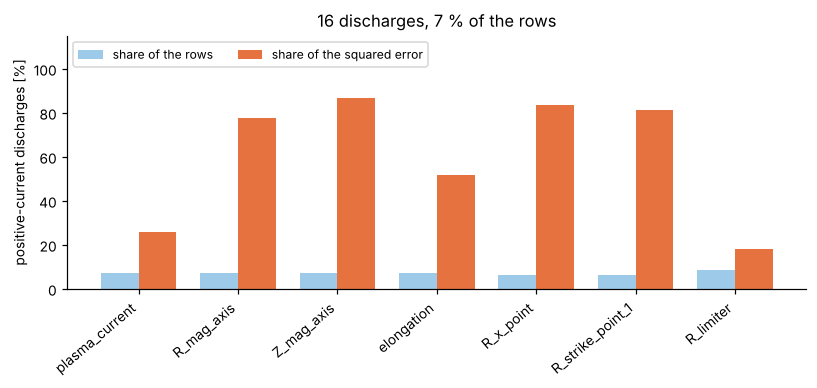

In [5]:
pol = numeric(table(F_DIST, "By current polarity"))
n_pos = int(re.search(r"(\d+) of 149 discharges are positive", read(F_DIST)).group(1))
assert n_pos == 16, n_pos  # the markdown above quotes 16
tp = ["plasma_current", "R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_strike_point_1", "R_limiter"]
p = pol.loc[tp, ["unit", "MAE positive current", "MAE negative current", "rows positive current", "sq err positive current"]].copy()
p.columns = ["unit", "MAE reversed", "MAE usual", "rows reversed %", "sq err reversed %"]
p["MAE ratio reversed/usual"] = p["MAE reversed"] / p["MAE usual"]
show(p, P1 + "; reversed = positive mean plasma current (16 discharges), usual = negative")

fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(len(p)); w = 0.38
ax.bar(x - w/2, p["rows reversed %"], w, label="share of the rows", color="#9ecae9")
ax.bar(x + w/2, p["sq err reversed %"], w, label="share of the squared error", color="#e6733f")
ax.set_xticks(x); ax.set_xticklabels(p.index, rotation=40, ha="right"); ax.set_ylabel("positive-current discharges [%]")
ax.set_title(f"{n_pos} discharges, {p['rows reversed %'].iloc[0]:.0f} % of the rows"); ax.set_ylim(0, 115); ax.legend(fontsize=8, ncol=2, loc="upper left"); plt.tight_layout(); plt.show()

### 2.3 First and last moments of a discharge

The error grows at the two ends. The reason is not established: the plasma current is small and changes fast there, so the reference reconstruction itself may be least reliable (hypothesis, not tested), and then the table shows disagreement with a label that is weakest at the ends.

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); first and last 2 % of the relative time of each discharge (about 925 rows each)
           unit  MAE first 2 %  MAE middle 96 %  MAE last 2 %  sq err first 2 %  sq err last 2 %  first/middle  last/middle
target                                                                                                                     
R_mag_axis   mm           1.54            0.321           1.7              23.4             26.9           4.8          5.3
Z_mag_axis   mm           1.38            0.335          1.91               7.2             77.9          4.12          5.7
elongation    -        0.00773          0.00543        0.0151               2.1             19.8          1.42         2.78
R_x_point    mm            NaN            0.202         0.313               NaN              0.9           NaN         1.55
R_limiter    mm

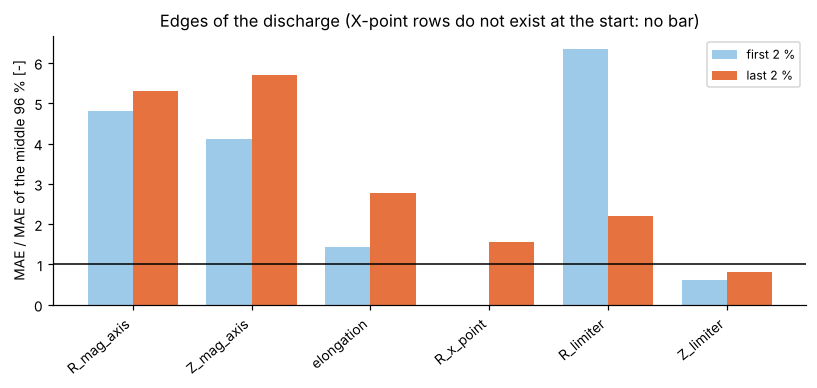

In [6]:
pos = numeric(table(F_DIST, "By position in the discharge"))
tq = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter", "Z_limiter"]
q = pos.loc[tq, ["unit", "MAE first 2 %", "MAE middle 96 %", "MAE last 2 %", "sq err first 2 %", "sq err last 2 %"]].copy()
q["first/middle"] = q["MAE first 2 %"] / q["MAE middle 96 %"]
q["last/middle"] = q["MAE last 2 %"] / q["MAE middle 96 %"]
show(q, P1 + "; first and last 2 % of the relative time of each discharge (about 925 rows each)")

fig, ax = plt.subplots(figsize=(7.5, 3.6)); x = np.arange(len(q)); w = 0.38
ax.bar(x - w/2, q["first/middle"], w, label="first 2 %", color="#9ecae9"); ax.bar(x + w/2, q["last/middle"], w, label="last 2 %", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(q.index, rotation=40, ha="right")
ax.set_ylabel("MAE / MAE of the middle 96 % [-]"); ax.set_title("Edges of the discharge (X-point rows do not exist at the start: no bar)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 2.4 Rare target values

The rows are cut into five equal groups by the reference value of each target (quintiles; Q1 lowest). A target whose error grows at an edge is a target whose
rare values are estimated worse.

R_mag_axis quintile edges of the reference value [mm]: Q1: 462.3 to 555.1; Q2: 555.1 to 559.9; Q3: 559.9 to 563.2; Q4: 563.2 to 566; Q5: 566 to 674.1


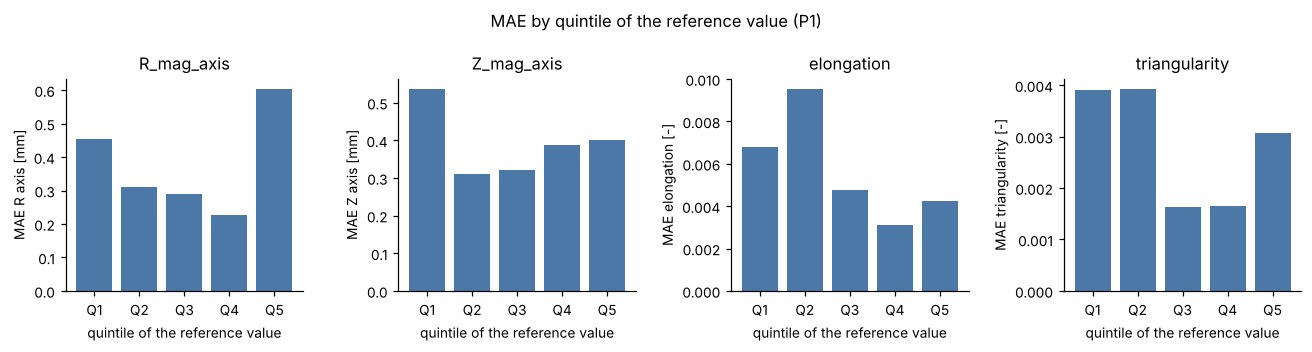

**Reading.** The worst group of rows by reference value is R_mag_axis: worst Q5 (0.604), best Q4 (0.228), ratio 2.6; Z_mag_axis: worst Q1 (0.537), best Q2 (0.31), ratio 1.7; elongation: worst Q2 (0.00954), best Q4 (0.00309), ratio 3.1; triangularity: worst Q2 (0.00393), best Q3 (0.00163), ratio 2.4. The radial axis is worse at both ends; the elongation is worst in the second quintile, where the low values of the unusual shapes lie (section 5); the file does not split that quintile further.

In [7]:
quint = {}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (h, label) in zip(axes, [("R_mag_axis (mm)", "R axis [mm]"), ("Z_mag_axis (mm)", "Z axis [mm]"), ("elongation", "elongation [-]"), ("triangularity", "triangularity [-]")]):
    qt = numeric(table(F_DIST, h, has=["quintile"]).rename(columns={"quintile": "q"}), text=("range of the true value",))
    quint[h.split(" (")[0]] = qt
    ax.bar(qt.index, qt["MAE"], color="#4c78a8")
    ax.set_title(h.split(" (")[0]); ax.set_ylabel(f"MAE {label}"); ax.set_xlabel("quintile of the reference value")
    if h == "R_mag_axis (mm)": print("R_mag_axis quintile edges of the reference value [mm]:", "; ".join(f"{i}: {r}" for i, r in qt["range of the true value"].items()))
plt.suptitle("MAE by quintile of the reference value (P1)"); plt.tight_layout(); plt.show()
parts = []
for t, qt in quint.items():
    w, b = qt["MAE"].idxmax(), qt["MAE"].idxmin()
    parts.append(f"{t}: worst {w} ({qt.loc[w,'MAE']:.3g}), best {b} ({qt.loc[b,'MAE']:.3g}), ratio {qt.loc[w,'MAE']/qt.loc[b,'MAE']:.1f}")
display(Markdown("**Reading.** The worst group of rows by reference value is " + "; ".join(parts) + ". The radial axis is worse at both ends; the elongation is worst in the second quintile, "
                 "where the low values of the unusual shapes lie (section 5); the file does not split that quintile further."))

### 2.5 The Limits section of the report, checked against the tables

`ipp1-distribution.md` ends with a Limits section. Its wording is shown as written, and every number in it is compared with the table value we just parsed.

In [8]:
limits = section(F_DIST, "Limits")
quote(limits, F_DIST)
checks = {
    "limited share of rows": f"{cfg.loc['R_mag_axis', 'rows limited']:.1f}%",
    "limited share of squared R axis error": f"{cfg.loc['R_mag_axis', 'sq err limited']:.1f}%",
    "reversed share of rows": f"{pol.loc['R_mag_axis', 'rows positive current']:.1f}%",
    "reversed share of squared R axis error": f"{pol.loc['R_mag_axis', 'sq err positive current']:.1f}%",
    "R_limiter MAE in the first 2 %": f"{pos.loc['R_limiter', 'MAE first 2 %']:.1f} mm",
    "Z_mag_axis share of squared error in the last 2 %": f"{pos.loc['Z_mag_axis', 'sq err last 2 %']:.1f}%",
    "R_mag_axis share of squared error in the last 2 %": f"{pos.loc['R_mag_axis', 'sq err last 2 %']:.1f}%",
}
flat = limits.replace("`", "")
for k, v in checks.items():
    print(f"{'OK ' if v in flat else 'MISSING'}  {k}: {v}")
assert all(v in flat for v in checks.values()), "a number in the Limits section does not match the table"

*Quoted from `results/ipp1-distribution.md`:*

- The headline MAE is an average over two very different regimes. The limited rows are 44.2% of the rows and carry 91.9% of the squared error of the radial axis (0.553 against 0.237 mm diverted).
- The 16 discharges with positive plasma current are 7.4% of the rows and carry 77.8% of it (1.73 against 0.269 mm). A shape absent from training is not handled.
- The worst localised weakness is the limiter point at the START of a discharge: `R_limiter` is 52.6 mm in the first 2 % against 8.28 mm in the middle, which is 40.5% of its squared error on 4.9% of its rows.
- The end of a discharge is the other edge: `Z_mag_axis` puts 77.9% of its squared error into the last 2 % of the rows, and `R_mag_axis` 26.9%.
- Rare target values are predicted worse at BOTH edges, not just one: the outer quintiles of `R_mag_axis` are 0.455 and 0.604 mm against 0.228 mm in the best quintile.
- These are out-of-fold rows of randomly held-out discharges. This file says nothing about a new campaign or regime; the discharge ids are chronological, so GroupKFold is the optimistic protocol.
- This file MEASURES the uneven distribution. It does not respond to it: no stratified folds and no reweighting were applied here.

OK   limited share of rows: 44.2%
OK   limited share of squared R axis error: 91.9%
OK   reversed share of rows: 7.4%
OK   reversed share of squared R axis error: 77.8%
OK   R_limiter MAE in the first 2 %: 52.6 mm
OK   Z_mag_axis share of squared error in the last 2 %: 77.9%
OK   R_mag_axis share of squared error in the last 2 %: 26.9%


## 3. Reading for REQ-007: limited plasma, reversed polarity, the limiter point

One table puts the three groups next to each other on the radial axis position, the headline target (P1).

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); target R_mag_axis
                          rows %  squared error %  MAE [mm] reference group  reference MAE [mm]  MAE ratio
group                                                                                                     
limited plasma              44.2             91.9     0.553        diverted               0.237       2.33
reversed polarity            7.4             77.8      1.73  usual polarity               0.269       6.43
last 2 % of a discharge      2.2             26.9       1.7     middle 96 %               0.321        5.3
first 2 % of a discharge     2.2             23.4      1.54     middle 96 %               0.321        4.8



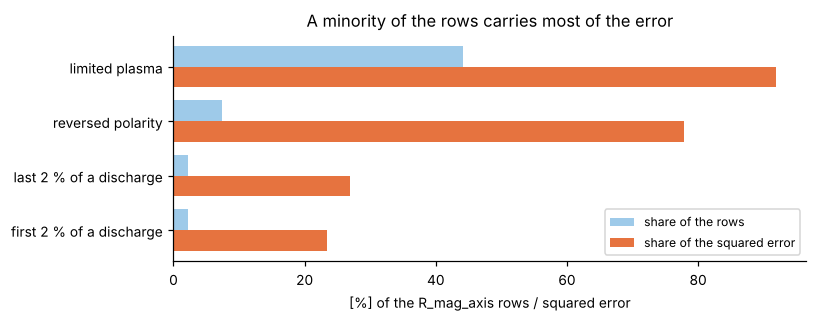

In [9]:
rows = []
def grp(name, mae, rows_pct, sq_pct, ref_name, ref_mae):
    rows.append({"group": name, "rows %": rows_pct, "squared error %": sq_pct, "MAE [mm]": mae, "reference group": ref_name, "reference MAE [mm]": ref_mae, "MAE ratio": mae / ref_mae})
r = "R_mag_axis"
grp("limited plasma", cfg.loc[r, "MAE limited"], cfg.loc[r, "rows limited"], cfg.loc[r, "sq err limited"], "diverted", cfg.loc[r, "MAE diverted"])
grp("reversed polarity", pol.loc[r, "MAE positive current"], pol.loc[r, "rows positive current"], pol.loc[r, "sq err positive current"], "usual polarity", pol.loc[r, "MAE negative current"])
grp("last 2 % of a discharge", pos.loc[r, "MAE last 2 %"], pos.loc[r, "rows last 2 %"], pos.loc[r, "sq err last 2 %"], "middle 96 %", pos.loc[r, "MAE middle 96 %"])
grp("first 2 % of a discharge", pos.loc[r, "MAE first 2 %"], pos.loc[r, "rows first 2 %"], pos.loc[r, "sq err first 2 %"], "middle 96 %", pos.loc[r, "MAE middle 96 %"])
share = pd.DataFrame(rows).set_index("group")
show(share, P1 + "; target R_mag_axis")

fig, ax = plt.subplots(figsize=(7.5, 3)); y = np.arange(len(share)); h = 0.38
ax.barh(y - h/2, share["rows %"], h, label="share of the rows", color="#9ecae9")
ax.barh(y + h/2, share["squared error %"], h, label="share of the squared error", color="#e6733f")
ax.set_yticks(y); ax.set_yticklabels(share.index); ax.invert_yaxis(); ax.set_xlabel("[%] of the R_mag_axis rows / squared error")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("A minority of the rows carries most of the error"); plt.tight_layout(); plt.show()

### 3.1 The limiter point

In [10]:
lim = overall.loc[["R_limiter", "Z_limiter"], ["unit", "MAE", "median", "p99", "nRMSE"]].copy()
lim["spread (SD) [mm]"] = spread.loc[["R_limiter", "Z_limiter"], "standard deviation"]
lim["MAE / SD"] = lim["MAE"] / lim["spread (SD) [mm]"]
lim["MAE first 2 % [mm]"] = pos.loc[["R_limiter", "Z_limiter"], "MAE first 2 %"]
lim["MAE middle [mm]"] = pos.loc[["R_limiter", "Z_limiter"], "MAE middle 96 %"]
show(lim, P1 + "; the limiter point exists only in the limited rows (19,012 of 42,972)")

rl = numeric(table(F_DIST, "R_limiter (mm)", has=["quintile"]).rename(columns={"quintile": "q"}), text=("range of the true value",)).dropna(subset=["MAE"])
display(Markdown(
    f"**Reading.** The limiter point is the weakest target: nRMSE {overall.loc['R_limiter','nRMSE']:.2f} (R) and {overall.loc['Z_limiter','nRMSE']:.2f} (Z) against "
    f"{overall.loc[['R_mag_axis','Z_mag_axis','R_x_point'],'nRMSE'].min():.2f} to {overall.loc[['R_mag_axis','Z_mag_axis','R_x_point'],'nRMSE'].max():.2f} "
    f"for the axis and the X-point. Its R value is estimated worst at the START of a discharge ({lim.loc['R_limiter','MAE first 2 % [mm]']:.1f} mm in the first 2 % "
    f"against {lim.loc['R_limiter','MAE middle [mm]']:.1f} mm in the middle) and for its rare large values "
    f"(top quintile, {rl.loc['Q5','range of the true value']} mm: MAE {rl.loc['Q5','MAE']:.1f} mm against {rl.loc['Q4','MAE']:.1f} mm in the quintile below, "
    f"{rl.loc['Q5','sq err']:.1f} % of the squared error on {rl.loc['Q5','rows']:.1f} % of the rows). "
    f"The limiter point exists only where the plasma touches the wall, so it is defined on {overall.loc['R_limiter','n']/overall.loc['R_mag_axis','n']*100:.0f} % of the rows and is a wall contact rather than a smooth shape feature. "
    f"Where the boundary slides along a nearly tangent wall, a small change of the equilibrium can move the contact a long way, so part of the large error may come from the definition of the point (hypothesis, not tested); "
    f"the distance of the plasma from the wall, which a controller needs, was not measured."))

Protocol: baseline MLP 256-256-128 on 24 inputs, 60 epochs, 5-fold GroupKFold by discharge, out-of-fold, 42,972 rows of 149 discharges (`ipp1-distribution.md`); the limiter point exists only in the limited rows (19,012 of 42,972)
          unit  MAE  median  p99  nRMSE  spread (SD) [mm]  MAE / SD  MAE first 2 % [mm]  MAE middle [mm]
target                                                                                                  
R_limiter   mm 10.8    2.64  145  0.318              89.6     0.121                52.6             8.28
Z_limiter   mm 22.3    9.32  171  0.273               153     0.145                  14             22.8



**Reading.** The limiter point is the weakest target: nRMSE 0.32 (R) and 0.27 (Z) against 0.08 to 0.16 for the axis and the X-point. Its R value is estimated worst at the START of a discharge (52.6 mm in the first 2 % against 8.3 mm in the middle) and for its rare large values (top quintile, 447.4 to 771.5 mm: MAE 24.1 mm against 7.4 mm in the quintile below, 58.6 % of the squared error on 20.6 % of the rows). The limiter point exists only where the plasma touches the wall, so it is defined on 44 % of the rows and is a wall contact rather than a smooth shape feature. Where the boundary slides along a nearly tangent wall, a small change of the equilibrium can move the contact a long way, so part of the large error may come from the definition of the point (hypothesis, not tested); the distance of the plasma from the wall, which a controller needs, was not measured.

## 4. What was done about it (protocol P2): measured, one response tested, not shipped

`ipp1-distribution.md` measures the unevenness and says plainly that **no stratified folds and no reweighting were applied** there. The one response that was
tested is a change of the **inputs** only, so that a deployment need not change how data are split: the sign of the 16 coil signals is used to fold
a reversed-polarity discharge onto the usual one (`ipp1-signcanon.md`, `analysis/` script on the recipe `cand` of `ipp1_final.py`).
Protocol: 5-fold GroupKFold inside the 119 development discharges (34,211 rows), 3 seeds, paired (each canonicalized run shares fold, seed and held-out
discharges with the plain run), then the 30 discharges kept aside, scored once per final model.

Protocol: indicator `-sign(sum of IPR01..16)` against the sign of the plasma current; development rows
                                           rows agree with sign(plasma_current)  fraction
check                                                                                    
clean inputs, development rows           34,211                          34,211  1.000000
provided noisy inputs, development rows  34,211                          34,211  1.000000

computed from the ratio table: reversed rows +64.2 % better, usual rows +20.2 % worse; file verdict: +64.2 % and +20.2 %
Protocol: development set (P2), pooled MAE of the canonicalized run divided by the plain run; below 1 = canonicalization better
                    unit  overall  reversed (positive current)  usual (negative current)
target                                                                                  
R_mag_axis            mm    0.851                        0.326                      1.23
Z_mag_axis          

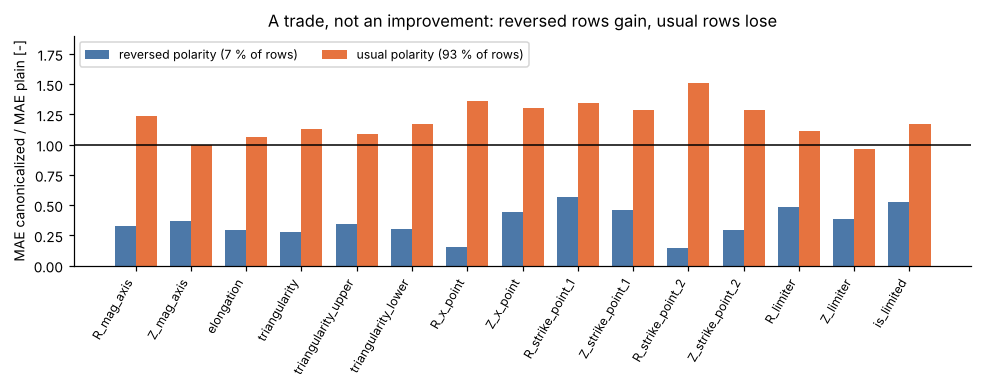

In [11]:
F_SC = "ipp1-signcanon.md"
ind = table(F_SC, "The indicator", has=["agree with sign(plasma_current)"])
show(ind.set_index("check"), "indicator `-sign(sum of IPR01..16)` against the sign of the plasma current; development rows", fmt="{:.6g}")

ratio = numeric(table(F_SC, "Development result", has=["overall", "positive current", "negative current"]))
ratio.columns = ["unit", "overall", "reversed (positive current)", "usual (negative current)"]
shape = [t for t in ratio.index if t != "plasma_current"]  # 15 shape targets; the current is a linear fit and unchanged
gain_rev = 1 - ratio.loc[shape, "reversed (positive current)"].mean()
cost_usual = ratio.loc[shape, "usual (negative current)"].mean() - 1
verdict = section(F_SC, "Verdict")
file_gain = float(re.search(r"Reversed-polarity rows.*?\*\*\+([\d.]+)%", verdict).group(1))
file_cost = float(re.search(r"Negative-current majority.*?\*\*\+([\d.]+)%", verdict).group(1))
print(f"computed from the ratio table: reversed rows {gain_rev*100:+.1f} % better, usual rows {cost_usual*100:+.1f} % worse; file verdict: +{file_gain} % and +{file_cost} %")
assert abs(gain_rev*100 - file_gain) < 0.2 and abs(cost_usual*100 - file_cost) < 0.2

show(ratio.loc[shape], "development set (P2), pooled MAE of the canonicalized run divided by the plain run; below 1 = canonicalization better")
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(shape)); w = 0.38
ax.bar(x - w/2, ratio.loc[shape, "reversed (positive current)"], w, label=f"reversed polarity ({pol.loc['R_mag_axis', 'rows positive current']:.0f} % of rows)", color="#4c78a8")
ax.bar(x + w/2, ratio.loc[shape, "usual (negative current)"], w, label=f"usual polarity ({100 - pol.loc['R_mag_axis', 'rows positive current']:.0f} % of rows)", color="#e6733f")
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(shape, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("MAE canonicalized / MAE plain [-]"); ax.set_title("A trade, not an improvement: reversed rows gain, usual rows lose"); ax.set_ylim(0, 1.9); ax.legend(fontsize=8, ncol=2, loc="upper left")
plt.tight_layout(); plt.show()

In [12]:
seeds = table(F_SC, "Development result", has=["variant", "mean"]).set_index("variant")
all16 = seeds["mean"].map(float)
agg_gain = 1 - all16["canon"] / all16["plain"]
locked = numeric(table(F_SC, "Locked test set", has=["plain", "canon", "ratio"]))
worse = locked.index[locked["ratio"] > 1.02].tolist()
lm = re.search(r"all16 plain (\d+\.\d+), canon (\d+\.\d+)", read(F_SC))
locked_all16 = (float(lm.group(1)), float(lm.group(2)))
show(seeds, "mean relative error over the 16 targets (`all16`), development set, per group of seeds", fmt="{:.4f}")
display(Markdown(
    f"**Reading.** Averaged over the 15 shape targets, canonicalization lowers the error of the reversed-polarity rows by **{gain_rev*100:.0f} %** and raises the error of the usual-polarity rows "
    f"(the {100 - pol.loc['R_mag_axis','rows positive current']:.0f} % majority) by **{cost_usual*100:.0f} %**. The aggregate `all16` improves by {agg_gain*100:.0f} % only because the heavy tail of the reversed discharges dominates it; "
    f"that number overstates the benefit and is not quoted as an improvement. On the 30 discharges kept aside (only 2 of them reversed, a more realistic mixture) `all16` is "
    f"{locked_all16[0]:.4f} plain against {locked_all16[1]:.4f} canonicalized, almost nothing, and {len(worse)} of {len(locked)} targets are worse by more than 2 %: {', '.join(worse)}. "
    f"**Not shipped.** The verdict in the file is: ship only if reversed-polarity discharges have to be served. The shipped model trains on the raw inputs."))

Protocol: mean relative error over the 16 targets (`all16`), development set, per group of seeds
        seeds 0 seeds 1 seeds 2    mean
variant                                
plain    0.0912  0.0994  0.0954  0.0953
canon    0.0638  0.0639  0.0648  0.0642



**Reading.** Averaged over the 15 shape targets, canonicalization lowers the error of the reversed-polarity rows by **64 %** and raises the error of the usual-polarity rows (the 93 % majority) by **20 %**. The aggregate `all16` improves by 33 % only because the heavy tail of the reversed discharges dominates it; that number overstates the benefit and is not quoted as an improvement. On the 30 discharges kept aside (only 2 of them reversed, a more realistic mixture) `all16` is 0.0590 plain against 0.0573 canonicalized, almost nothing, and 10 of 16 targets are worse by more than 2 %: Z_mag_axis, triangularity, triangularity_upper, triangularity_lower, Z_x_point, R_strike_point_1, Z_strike_point_1, R_limiter, Z_limiter, is_limited. **Not shipped.** The verdict in the file is: ship only if reversed-polarity discharges have to be served. The shipped model trains on the raw inputs.

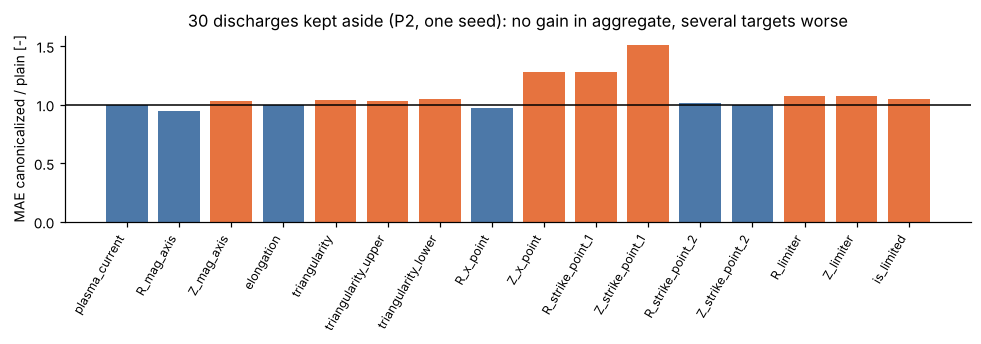

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.2)); x = np.arange(len(locked))
ax.bar(x, locked["ratio"], color=np.where(locked["ratio"] > 1.02, "#e6733f", "#4c78a8"))
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels(locked.index, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("MAE canonicalized / plain [-]"); ax.set_title("30 discharges kept aside (P2, one seed): no gain in aggregate, several targets worse")
plt.tight_layout(); plt.show()

### 4.1 The shipped model on the same groups, and why the kept-aside set is easy

`ipp1-final.md` scores the baseline network and the shipped candidate on the 30 kept-aside discharges, cut by configuration and polarity. Read this
with two warnings: the 30 discharges hold **only 2 reversed-polarity discharges (591 rows)**, so the reversed column says nothing reliable, and the set is
**easier than the development average** (development against kept-aside nRMSE, table below): the same recipes score lower there than in the development cross-validation.

Protocol: P2: trained on 119 development discharges, scored on 30 discharges kept aside (8,761 rows), clean inputs, one seed (`ipp1-final.md`); target R_mag_axis, MAE [mm]
                              rows  discharges  baseline  candidate  candidate / baseline
divertor                      5207          30     0.202     0.0929                0.4599
limited                       3554          30      0.46      0.192                0.4174
usual polarity (negative)     8170          28     0.257       0.11                 0.428
reversed polarity (positive)   591           2     0.998      0.454                0.4549
first 2 % of the discharge     189          30      1.65      0.538                0.3261
middle                        8383          30     0.256      0.114                0.4453
last 2 % of the discharge      189          30      1.21      0.578                0.4777

Protocol: development = pooled out-of-fold over 119 discharges, kept aside = 30 discharges (`ipp1-final.md`

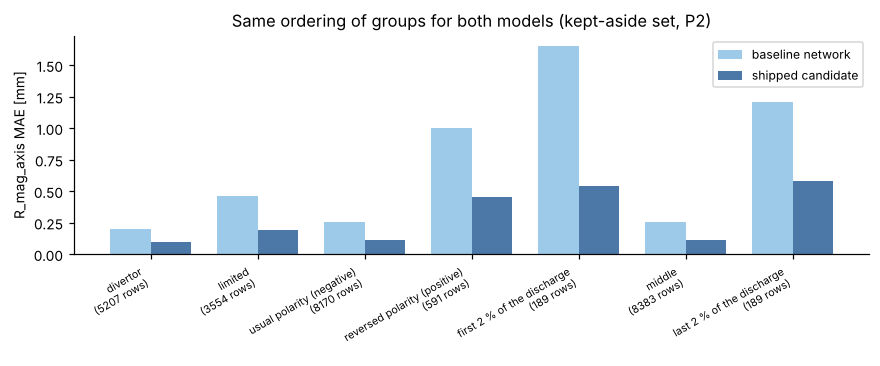

In [14]:
F_FIN = "ipp1-final.md"
P2 = "P2: trained on 119 development discharges, scored on 30 discharges kept aside (8,761 rows), clean inputs, one seed (`ipp1-final.md`)"

def breakdown(prefix, col_base="baseline MLP clean", col_cand="candidate, plain clean", target="R_mag_axis"):
    for h, df in md_tables(F_FIN):
        if h.startswith(prefix):
            n = re.search(r"\((\d+) rows, (\d+) discharges\)", h)
            d = numeric(df)
            return {"rows": int(n.group(1)), "discharges": int(n.group(2)), "baseline": d.loc[target, col_base], "candidate": d.loc[target, col_cand]}
    raise KeyError(prefix)

groups = {"divertor": "configuration: divertor", "limited": "configuration: limited", "usual polarity (negative)": "polarity: negative", "reversed polarity (positive)": "polarity: positive",
          "first 2 % of the discharge": "relative time: first 2 %", "middle": "relative time: middle", "last 2 % of the discharge": "relative time: last 2 %"}
lk = pd.DataFrame({g: breakdown(p) for g, p in groups.items()}).T
lk["candidate / baseline"] = lk["candidate"] / lk["baseline"]
assert (lk.loc["reversed polarity (positive)", "discharges"], lk.loc["reversed polarity (positive)", "rows"]) == (2, 591)  # quoted in the markdown above
show(lk, P2 + "; target R_mag_axis, MAE [mm]", fmt="{:.4g}")

dev = numeric(table(F_FIN, "Development set: pooled out-of-fold scores"), text=("inputs", "recipe"))
dev.index.name = "recipe"
devc = dev[dev["inputs"] == "clean"]
loc_base = numeric(table(F_FIN, "baseline MLP, clean inputs")); loc_cand = numeric(table(F_FIN, "candidate, plain, clean inputs"))
nr = lambda pre: float(re.search(r"mean nRMSE over 16 targets ([\d.]+)", [h for h, _ in md_tables(F_FIN) if h.startswith(pre)][0]).group(1))
cmp_ = pd.DataFrame({
    "development CV, R axis [mm]": [devc.loc["baseline MLP", "R_mag_axis MAE"], devc.loc["candidate, plain", "R_mag_axis MAE"]],
    "kept aside, R axis [mm]": [loc_base.loc["R_mag_axis", "MAE"], loc_cand.loc["R_mag_axis", "MAE"]],
    "development CV, mean nRMSE (16)": [devc.loc["baseline MLP", "mean nRMSE (16)"], devc.loc["candidate, plain", "mean nRMSE (16)"]],
    "kept aside, mean nRMSE (16)": [nr("baseline MLP, clean inputs"), nr("candidate, plain, clean inputs")]}, index=["baseline MLP", "shipped candidate (clean)"])
cmp_["nRMSE lower on the kept-aside set by %"] = (1 - cmp_["kept aside, mean nRMSE (16)"] / cmp_["development CV, mean nRMSE (16)"]) * 100
show(cmp_, "development = pooled out-of-fold over 119 discharges, kept aside = 30 discharges (`ipp1-final.md`)", fmt="{:.4g}")

fig, ax = plt.subplots(figsize=(8, 3.4)); x = np.arange(len(lk)); w = 0.38
ax.bar(x - w/2, lk["baseline"], w, label="baseline network", color="#9ecae9"); ax.bar(x + w/2, lk["candidate"], w, label="shipped candidate", color="#4c78a8")
ax.set_xticks(x); ax.set_xticklabels([f"{g}\n({int(n)} rows)" for g, n in zip(lk.index, lk["rows"])], fontsize=7, rotation=30, ha="right")
ax.set_ylabel("R_mag_axis MAE [mm]"); ax.set_title("Same ordering of groups for both models (kept-aside set, P2)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 5. Unusual shapes: leave a whole family out (protocol P3)

Source: `ipp1-unusual-shapes.md` (`analysis/ipp1_unusual_shapes.py`, committed figure `ipp1-unusual-shapes.png`).
Each discharge is described by its median elongation and median triangularity; KMeans on the ranks of the two values forms families. For each family the network is
trained on all other discharges and tested on the family. The reference is the error on the **same discharges** from the usual random 5-fold split, so the factor
is caused by the unseen shape and not by the choice of discharges. The network is the shared 256-256-128 network, 60 epochs, one initialization per group. The 18 unusual discharges are those with a low median elongation; elongation values below 1 are unusual for a tokamak plasma and the organizers' formula is not recorded here, so we do not interpret them physically (to be checked with the institute).

*Quoted from `results/ipp1-unusual-shapes.md`:*

Nearly all discharges lie in one tight group (median elongation 1.75 to 1.82, triangularity 0.33 to 0.40). 18 discharges are really different
(median elongation 1.0 to 1.74, triangularity 0.02 to 0.33); they all fall into cluster 0, and they are 18 of the 23 discharges of the low elongation group. Clusters 1 to 3 are therefore subgroups
of ordinary shapes. The high triangularity group (median 0.38 against 0.36 for everything) is only the upper edge of the ordinary group and **is not
a rare shape**.

range = (random split, family out) and quotient = factor, within rounding: True
Protocol: P3: family held out, network trained on all other discharges; reference = same discharges in the random 5-fold split (`ipp1-unusual-shapes.md`)
                                                        discharges R axis [mm] ref->out Z axis [mm] ref->out elongation [-] ref->out limiter R [mm] ref->out
Held out                                                                                                                                                    
cluster 0 (contains the 18 odd shapes)                        34.0          0.53 -> 1.1         0.48 -> 0.99        0.0075 -> 0.0136            11.2 -> 34.1
cluster 1                                                     39.0         0.43 -> 0.75         0.48 -> 0.76        0.0063 -> 0.0081            10.3 -> 11.5
cluster 2                                                     33.0         0.38 -> 0.44         0.38 -> 0.47        0.0056 -> 0.0064      

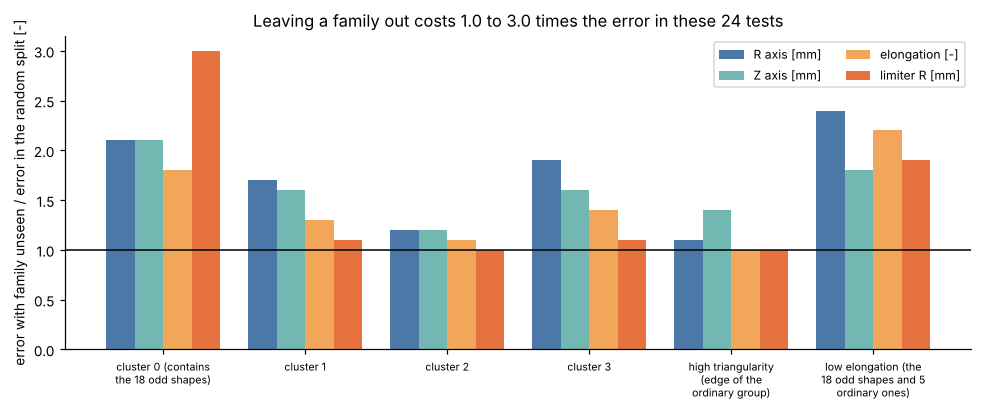

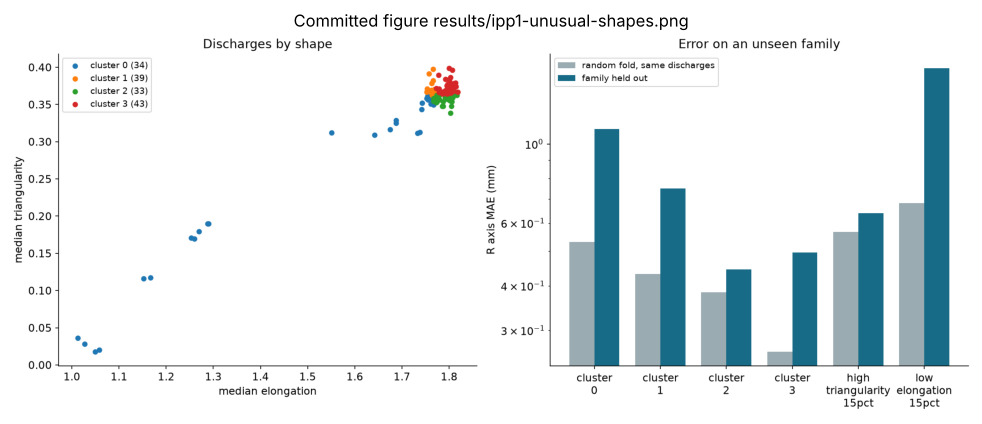

In [15]:
import textwrap
F_US = "ipp1-unusual-shapes.md"
P3 = "P3: family held out, network trained on all other discharges; reference = same discharges in the random 5-fold split (`ipp1-unusual-shapes.md`)"
quote(section(F_US, "What the 149 discharges look like"), F_US)
n_odd = int(re.search(r"(\d+) discharges are really different", section(F_US, "What the 149 discharges look like")).group(1))
assert n_odd == 18, n_odd  # quoted in the text of this section and in the answer

us = table(F_US, "Result", has=["Held out"]).set_index("Held out")
cols = {"R axis (mm)": "R axis [mm]", "Z axis (mm)": "Z axis [mm]", "elongation": "elongation [-]", "limiter R (mm)": "limiter R [mm]"}
pat = re.compile(r"([\d.]+) to ([\d.]+) \(([\d.]+)x\)")
parsed = {name: us[c].map(lambda s: tuple(map(float, pat.match(s).groups()))) for c, name in cols.items()}
factor = pd.DataFrame({n: s.map(lambda t: t[2]) for n, s in parsed.items()})
ref = pd.DataFrame({n: s.map(lambda t: t[0]) for n, s in parsed.items()})
out = pd.DataFrame({n: s.map(lambda t: t[1]) for n, s in parsed.items()})
# The first number of each cell is the reference error, the second the family-out error: their quotient must reproduce the stated factor.
ok = ((out / ref - factor).abs() <= 0.12).values.all()
print("range = (random split, family out) and quotient = factor, within rounding:", ok)
assert ok
fam = pd.concat({"discharges": us["Discharges"].map(float), **{f"{n} ref->out": (ref[n].map("{:.3g}".format) + " -> " + out[n].map("{:.3g}".format)) for n in cols.values()}}, axis=1)
print("Protocol:", P3); print(fam.to_string()); print()
show(factor.add_prefix("x "), P3 + "; factor = family out / random split, same discharges", fmt="{:.1f}")

fig, ax = plt.subplots(figsize=(9, 3.8)); x = np.arange(len(factor)); w = 0.2
for i, (n, colr) in enumerate(zip(factor.columns, ["#4c78a8", "#72b7b2", "#f2a65a", "#e6733f"])):
    ax.bar(x + (i - 1.5) * w, factor[n], w, label=n, color=colr)
ax.axhline(1, color="k", lw=1); ax.set_xticks(x); ax.set_xticklabels([textwrap.fill(s, 20) for s in factor.index], fontsize=7)
ax.set_ylabel("error with family unseen / error in the random split [-]"); ax.set_title(f"Leaving a family out costs {factor.values.min():.1f} to {factor.values.max():.1f} times the error in these {factor.size} tests"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

img = plt.imread(RES / "ipp1-unusual-shapes.png"); READ.add("ipp1-unusual-shapes.png")
fig, ax = plt.subplots(figsize=(9, 5)); ax.imshow(img); ax.axis("off"); ax.set_title("Committed figure results/ipp1-unusual-shapes.png"); plt.tight_layout(); plt.show()

In [16]:
odd = us.index[us.index.str.startswith("low elongation")][0]
c0 = us.index[us.index.str.startswith("cluster 0")][0]
hi = us.index[us.index.str.startswith("high triangularity")][0]
display(Markdown(
    f"**Reading.** Leaving a family out makes the error {factor.values.min():.1f} to {factor.values.max():.1f} times larger, "
    f"{np.median(factor.values):.1f} times at the median over the {factor.size} values above. The family that is mostly the odd shapes ('{odd}') goes from "
    f"{ref.loc[odd,'R axis [mm]']:.2f} to {out.loc[odd,'R axis [mm]']:.2f} mm on the radial axis and from {ref.loc[odd,'elongation [-]']:.4f} to "
    f"{out.loc[odd,'elongation [-]']:.4f} in elongation, and cluster 0 ('{c0}') has the largest limiter factor, {factor.loc[c0,'limiter R [mm]']:.1f} times. "
    f"The high triangularity family is only the upper edge of the ordinary group and is not a rare shape; its factors are {factor.loc[hi].min():.1f} to {factor.loc[hi].max():.1f}."))
quote(section(F_US, "Limits"), F_US)
# Since that report was written the 18 oddest discharges were also left out alone; its numbers are read from their own committed file.
F_HO = "ipp1-unusual-heldout.md"
ho = numeric(table(F_HO, "odd18"))
early = re.search(r"(\d+) of the (\d+) ids lie in the lowest quarter", read(F_HO)).groups()
ho_r, ho_e = ho.loc["R_mag_axis"], ho.loc["elongation"]
display(Markdown(
    f"**The {early[1]} oddest discharges left out alone** (`{F_HO}`, baseline network, 3 seeds): radial axis {ho_r['MAE random folds']:.2f} mm in the random folds on the same discharges against "
    f"{ho_r['MAE left out']:.2f} mm with them left out ({ho_r['factor']:.1f} times), elongation {ho_e['MAE random folds']:.4f} against {ho_e['MAE left out']:.4f} ({ho_e['factor']:.1f} times). "
    f"{early[0]} of the {early[1]} ids lie in the lowest quarter of the discharge numbers, so the factor mixes the shape with the early part of the campaign order. "
    f"This is still not a test of shapes outside the range of the data."))

**Reading.** Leaving a family out makes the error 1.0 to 3.0 times larger, 1.5 times at the median over the 24 values above. The family that is mostly the odd shapes ('low elongation (the 18 odd shapes and 5 ordinary ones)') goes from 0.68 to 1.63 mm on the radial axis and from 0.0100 to 0.0225 in elongation, and cluster 0 ('cluster 0 (contains the 18 odd shapes)') has the largest limiter factor, 3.0 times. The high triangularity family is only the upper edge of the ordinary group and is not a rare shape; its factors are 1.0 to 1.4.

*Quoted from `results/ipp1-unusual-shapes.md`:*

- The random split is itself optimistic: discharge ids are chronological, so neighbours of every test discharge are in training
  (`docs/review-findings.md`). The factors measure the loss from removing a whole family, not the total error on a new tokamak scenario.
- Only 18 discharges are truly unusual and they were never held out alone (cluster 0 and the low elongation group mix them with 16 and 5 ordinary ones),
  and the extreme elongation near 1.0 was never tested as an unseen extreme. The result says nothing about shapes outside the range of the data.
- One initialization per group, no repeated runs; with 23 to 43 discharges per group a factor of 1.1x to 1.3x is within noise.

**The 18 oddest discharges left out alone** (`ipp1-unusual-heldout.md`, baseline network, 3 seeds): radial axis 0.91 mm in the random folds on the same discharges against 2.26 mm with them left out (2.5 times), elongation 0.0122 against 0.0219 (1.8 times). 14 of the 18 ids lie in the lowest quarter of the discharge numbers, so the factor mixes the shape with the early part of the campaign order. This is still not a test of shapes outside the range of the data.

## 6. Provenance check and answer

In [17]:
missing, n_read, git_ok = tracked_check()
print(f"{n_read} results files read:", ", ".join(sorted(READ)))
print("all of them are tracked in git:", (not missing) if git_ok else "git not available here, cannot check")
assert not missing, missing

7 results files read: ipp1-data-checks.md, ipp1-distribution.md, ipp1-final.md, ipp1-signcanon.md, ipp1-unusual-heldout.md, ipp1-unusual-shapes.md, ipp1-unusual-shapes.png
all of them are tracked in git: True


In [18]:
display(Markdown(f"""
## Answer

**Yes, the data are uneven, and the headline mean hides it.** On the radial axis position (baseline network, out-of-fold, P1) the mean absolute difference from the reference reconstruction is {overall.loc['R_mag_axis','MAE']:.2f} mm,
the median {overall.loc['R_mag_axis','median']:.2f} mm, 99 % of the rows are below {overall.loc['R_mag_axis','p99']:.1f} mm and the worst row is {overall.loc['R_mag_axis','max']:.0f} mm.
Limited plasma is {cfg.loc['R_mag_axis','rows limited']:.0f} % of the rows and carries {cfg.loc['R_mag_axis','sq err limited']:.0f} % of the squared error ({share.loc['limited plasma','MAE ratio']:.1f} times the diverted error);
the {n_pos} positive-current ('reversed') discharges are {pol.loc['R_mag_axis','rows positive current']:.1f} % of the rows and carry {pol.loc['R_mag_axis','sq err positive current']:.0f} %;
the last 2 % of a discharge are {pos.loc['R_mag_axis','rows last 2 %']:.0f} % of the rows and carry {pos.loc['R_mag_axis','sq err last 2 %']:.0f} %. The limiter point is the weakest target
(nRMSE {overall.loc['R_limiter','nRMSE']:.2f} and {overall.loc['Z_limiter','nRMSE']:.2f}).

**What we did about it.** The unevenness is measured, not corrected by reweighting or stratified folds. The one response tested, folding reversed polarity onto the usual one with the sign of the coil signals,
lowers the error of the reversed rows by {gain_rev*100:.0f} % and raises that of the usual rows by {cost_usual*100:.0f} %; it is a trade, it is **not shipped**, and it matters only if reversed-polarity discharges have to be served.
The 30 kept-aside discharges are easier than the development average (nRMSE {cmp_.loc['shipped candidate (clean)','nRMSE lower on the kept-aside set by %']:.0f} % lower for the shipped model) and hold only {lk.loc['reversed polarity (positive)','discharges']:.0f} reversed discharges, so they cannot settle this.

**Unusual shapes.** A whole family of shapes left out of training costs {factor.values.min():.1f} to {factor.values.max():.1f} times the error (median {np.median(factor.values):.1f} times), in these tests no collapse (not a general claim); but only {n_odd} discharges are truly unusual; when they are left out alone (baseline network) the radial axis error rises {ho_r['factor']:.1f} times, mixed with their early place in the campaign order; the random split is itself optimistic (the discharge numbers appear to follow time; not confirmed with the organizers), and nothing is claimed about shapes outside the range of the data.
"""))


## Answer

**Yes, the data are uneven, and the headline mean hides it.** On the radial axis position (baseline network, out-of-fold, P1) the mean absolute difference from the reference reconstruction is 0.38 mm,
the median 0.15 mm, 99 % of the rows are below 3.7 mm and the worst row is 64 mm.
Limited plasma is 44 % of the rows and carries 92 % of the squared error (2.3 times the diverted error);
the 16 positive-current ('reversed') discharges are 7.4 % of the rows and carry 78 %;
the last 2 % of a discharge are 2 % of the rows and carry 27 %. The limiter point is the weakest target
(nRMSE 0.32 and 0.27).

**What we did about it.** The unevenness is measured, not corrected by reweighting or stratified folds. The one response tested, folding reversed polarity onto the usual one with the sign of the coil signals,
lowers the error of the reversed rows by 64 % and raises that of the usual rows by 20 %; it is a trade, it is **not shipped**, and it matters only if reversed-polarity discharges have to be served.
The 30 kept-aside discharges are easier than the development average (nRMSE 35 % lower for the shipped model) and hold only 2 reversed discharges, so they cannot settle this.

**Unusual shapes.** A whole family of shapes left out of training costs 1.0 to 3.0 times the error (median 1.5 times), in these tests no collapse (not a general claim); but only 18 discharges are truly unusual; when they are left out alone (baseline network) the radial axis error rises 2.5 times, mixed with their early place in the campaign order; the random split is itself optimistic (the discharge numbers appear to follow time; not confirmed with the organizers), and nothing is claimed about shapes outside the range of the data.
